# Figure 3 - ModelNet10 Orientation 

In [1]:
# access fsw3d library by adding project root to sys.path
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import time
import pickle
from pathlib import Path

### standard libraries
import numpy as np
import matplotlib.pyplot as plt

### extra libraries
import trimesh

### fsw3d
from fast_volume_align_ot import utils, transforms, signals, alignments, distances

In [2]:
### Constrants and helper functions

COLORS = {
    'l2': 'darkgrey',
    'sw': '#8FB996',
    'rfsw': '#7C8ED0'
}

def voxelize_and_center_model(model_path, N, N_mesh):

    ### N is desired voxels in one dimension
    ### N_mesh is voxels for building the model
    ### --> just a lazy way to mask the volume for now

    # load mesh
    mesh = trimesh.load(model_path)

    # normalize to unit cube centered at origin
    mesh.vertices -= mesh.bounding_box.centroid
    mesh.vertices /= mesh.extents.max()

    # voxelize to roughly N_mesh^3 resolution
    voxels = mesh.voxelized(
        pitch=1/N_mesh
    ).fill()

    grid = voxels.matrix.astype(np.uint8)

    # --------------------------------------------------
    # center pad/crop to exact N^3
    # --------------------------------------------------

    out = np.zeros((N, N, N), dtype=np.uint8)

    sx, sy, sz = grid.shape

    # crop if too large
    grid = grid[
        :min(sx, N),
        :min(sy, N),
        :min(sz, N)
    ]

    sx, sy, sz = grid.shape

    ox = (N - sx) // 2
    oy = (N - sy) // 2
    oz = (N - sz) // 2

    out[
        ox:ox+sx,
        oy:oy+sy,
        oz:oz+sz
    ] = grid   

    return out


def in_region(R, theta_max, phi_min, phi_max):
    x, y, z = R[:, 2]
    phi = np.arctan2(y, x)

    in_cone = z > np.cos(theta_max)
    in_wedge = phi_min < phi < phi_max

    if in_cone and in_wedge:
        out = 1
    else:
        out = 0

    return out


def get_orientation_count(aligned_data, theta_max=np.pi, phi_min=-np.pi, phi_max=np.pi):

    orientation_count = []
    n_vols = len(aligned_data)
    thetas = np.linspace(0, theta_max, num=50, endpoint=True)

    for tm in thetas:
        count = np.zeros(n_vols)

        for k in range(n_vols):
            count[k] = in_region(aligned_data[k].R, tm, phi_min, phi_max)

        orientation_count.append(np.sum(count))

    return np.array(orientation_count)

In [ ]:
########################################################

### First you need to download the ModelNet10 Dataset
### Download 10-Class Orientation-aligned Subset
### link: https://modelnet.cs.princeton.edu/

########################################################

In [ ]:
### INPUTRS ###
N = 64  # voxel grid resolution / (bounding box) ?
N_mesh = 42  # size of mesh reconstruction

d = 3
dx = 1

grid = transforms.Grids(N=N)

use_metric = ['L2', 'SW', 'RFSW']
use_correlation=False
###

model_items = ['bathtub', 
               'bed', 
               'chair',
               'desk',
               'dresser', 
               'monitor',
               'night_stand', 
               'sofa', 
               'table', 
               'toilet']

### In this experiment, we compute rotational alignment for each category.
### First we pick a reference model from each category to be the model
### that minimizes the Euclidean distance to the average model.
### Then we compute the alignemnts. This can take some time.

model_avg = {item: 0 for item in model_items}

for item in model_items:

    t = time.time()
    
    data_dir = Path('../ModelNet10_Data/ModelNet10/{}/test/'.format(item))
    files = sorted(list(data_dir.glob("*.off")))
    n_vols = len(files)
    print(item, 'n_volumes = ', n_vols)

    voxel_grids = []
    
    t = time.time()
    for path in files:
        m = voxelize_and_center_model(path, N, N_mesh)
        voxel_grids.append(m)
    print(item, ' models loaded: ', time.time() - t) 
    
    voxel_grids = np.stack(voxel_grids)
    avg = np.mean(voxel_grids, axis=0)
    dists = np.zeros(voxel_grids.shape[0])
    
    for idx, vol in enumerate(voxel_grids):
        dists[idx] = np.linalg.norm(avg - vol)
    
    a_min = np.argmin(dists)
    model_avg[item] = a_min

    f = voxel_grids[a_min]
    f = signals.Signal(f, d=d, dx=dx).preprocess_signals()[0]
    gs = signals.Signal(voxel_grids, d=d, dx=dx).preprocess_signals()

    alignments_l2 = []
    alignments_sw = []
    alignments_rfsw = []

    ### Now compute the alignments for each model
    print('computing alignments')
    t0 = time.time()
    
    for k in range(n_vols):

        t = time.time()

        ### apply a rotation to the volume
        g = gs[k]
        g = np.rot90(g, 1)
        g = np.ascontiguousarray(g)  ### avoid finufft c-contiguous error message
    
        if 'L2' in use_metric:
            alignments_l2.append(alignments.Alignment(f, g, grid, 'L2', use_correlation))
        
        if 'SW' in use_metric:
            alignments_sw.append(alignments.Alignment(f, g, grid, 'SW', use_correlation))
    
        if 'RFSW' in use_metric:
            alignments_rfsw.append(alignments.Alignment(f, g, grid, 'RFSW', use_correlation))

        print(item, 'model', k, 'alignments computed: ', time.time() - t)
    
    output_dict = {'alignments_l2': alignments_l2, 
                   'alignments_sw': alignments_sw, 
                   'alignments_rfsw': alignments_rfsw}
    
    save_path = '../Output/{0}_{1}_alignments.pkl'.format(item, N)
    
    utils.save_pkl(save_path, output_dict)

    print(item, ' runtime ', time.time() - t0)
    print('\n')

In [3]:
### load the data after computing the alignments in the previous step

model_items = ['bathtub', 
               'bed', 
               'chair',
               'desk',
               'dresser', 
               'monitor',
               'night_stand', 
               'sofa', 
               'table', 
               'toilet']

save_paths = ['../Output/ModelNet_output/bathtub_64_alignments.pkl',
              '../Output/ModelNet_output/bed_64_alignments.pkl',
              '../Output/ModelNet_output/chair_64_alignments.pkl',
              '../Output/ModelNet_output/desk_64_alignments.pkl',
              '../Output/ModelNet_output/dresser_64_alignments.pkl',
              '../Output/ModelNet_output/monitor_64_alignments.pkl',
              '../Output/ModelNet_output/night_stand_64_alignments.pkl',
              '../Output/ModelNet_output/sofa_64_alignments.pkl',
              '../Output/ModelNet_output/table_64_alignments.pkl',
              '../Output/ModelNet_output/toilet_64_alignments.pkl']

alignment_scores = {model_items[idx]: utils.load_pkl(save_paths[idx]) for idx, m in enumerate(save_paths)}

In [4]:
### Parameters for orientation estimation

phi_min = -np.pi/2
phi_max = np.pi/2

# phi_min = -np.pi
# phi_max = np.pi

# theta_max = np.pi/4
theta_max = np.pi
thetas = np.linspace(0, theta_max, num=50, endpoint=True)

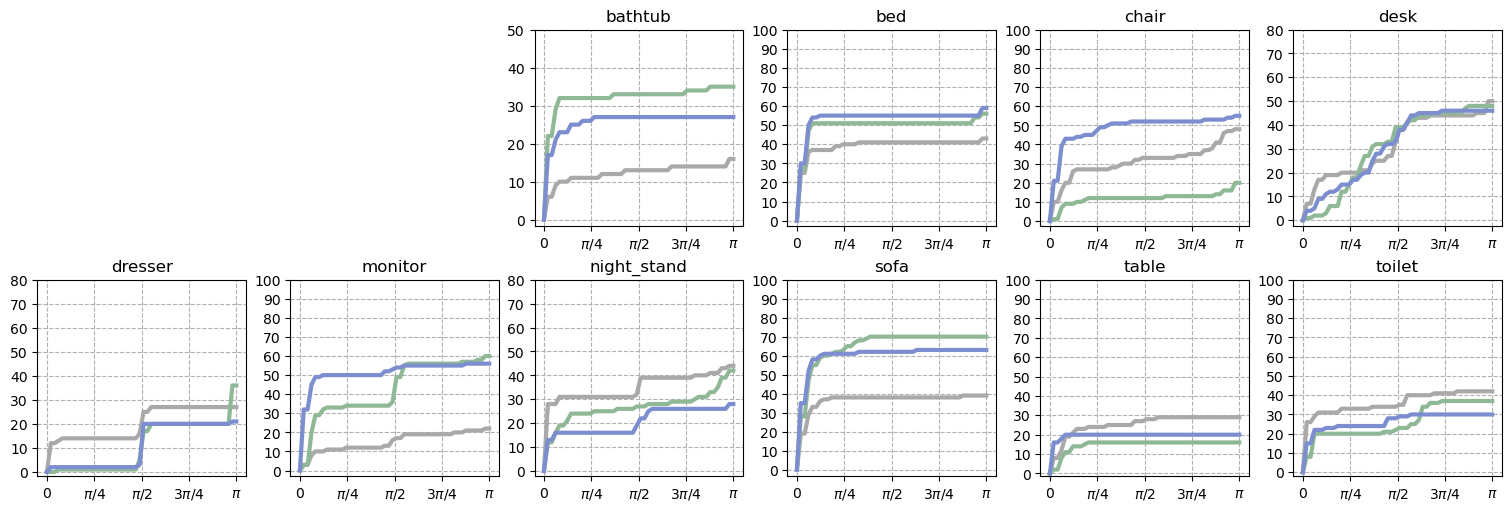

In [5]:
positions = [(r, c) for r in range(2) for c in range(6)][2:]

fig, axs = plt.subplots(2, 6, figsize=(15, 5), constrained_layout=True)

for idx, m in enumerate(alignment_scores):

    r, c = positions[idx]
    
    a_l2 = alignment_scores[m]['alignments_l2']
    a_sw = alignment_scores[m]['alignments_sw']
    a_rfsw = alignment_scores[m]['alignments_rfsw']

    o_l2 = get_orientation_count(a_l2, theta_max, phi_min, phi_max)
    o_sw = get_orientation_count(a_sw, theta_max, phi_min, phi_max)
    o_rfsw = get_orientation_count(a_rfsw, theta_max, phi_min, phi_max)

    n_vols = len(a_l2)

    axs[r, c].plot(thetas, o_l2, color=COLORS['l2'], linewidth=3, label='Euclidean')
    axs[r, c].plot(thetas, o_sw, color=COLORS['sw'], linewidth=3, label='sliced 2-Wasserstein')
    axs[r, c].plot(thetas, o_rfsw, color=COLORS['rfsw'], linewidth=3, label='ramp-filtered sliced 2-Wasserstein')

    x_ticks = [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi]
    x_labels = [r"$0$", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$"]
    
    axs[r, c].set_xticks(x_ticks)
    axs[r, c].set_xticklabels(x_labels)
    
    y_ticks = np.arange(0, n_vols+1, 10)
    axs[r, c].set_yticks(y_ticks)

    axs[r, c].grid(which='major', linestyle='--')
    axs[r, c].set_title(m)

axs[0, 0].axis("off")
axs[0, 1].axis("off")

# plt.savefig('Output/model_orientation_accuracy.png', dpi=200, transparent=True)

plt.show()